## CS4287 Assignment 1: Robin vs. Not-Robin Classification with AlexNet and Mini-VGG
### 1. Setup and hyperparameters

In [ ]:
# Group 11: Ciara Molloy (23376023), Ellis Mullen (21334498), Mohamed Amine Ait el Houssein (23397403)
# Code executes to the end without error: yes (runtime 4hrs)
# Third-party source: None


import os, json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

SEED = 42 #seed for random funtions (will run the same each time)
IMG_SIZE = 128 #sets image size 128*128
BATCH_SIZE = 32 #sets batch size
EPOCHS = 30 #sets epochs 
LEARNING_RATE = 0.001 #sets learning rate
N_FOLDS = 5 #sets the number of k folds

print("GPU:", tf.config.list_physical_devices('GPU'))

GPU: []


### 2. Loading the dataset split

In [ ]:
df = pd.read_csv("bird_dataset.csv") #reads our custom data set from the csv
df["filepath"] = df["filepath"].str.replace("\\", "/", regex=False)#changes the filepath into something the program can read.
df["fold"] = df["fold"].astype(str) 
assert df["filepath"].map(os.path.exists).all(), "Some image paths were not found"

test_df = df[df["fold"] == "test"]
cv_df = df[df["fold"] != "test"]
print(len(cv_df), "images for cross-validation,", len(test_df), "held-out test images")

1560 images for cross-validation, 391 held-out test images


### 3. Input pipeline

In [ ]:
def load_image(path, label):
    #loads image
    img = tf.io.read_file(path)#reads the file from the file path
    img = tf.io.decode_image(img, channels=3, expand_animations=False)#decodes the image
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))#resizes the image to 128*128 so it can be run though the model
    return img, label

def make_ds(frame, shuffle):
    #makes dataset
    ds = tf.data.Dataset.from_tensor_slices((frame["filepath"].values, frame["label"].values))#makes the tensorflow dataset
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()#stores data in cache layer for effieciency
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED)#shuffles the training data (uses a seed for reproducability)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

### 4. Model definitions

In [ ]:
def compile_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
                 #,
                 #keras.metrics.Precision(name='precision'),
                 #keras.metrics.Recall(name='recall')])
    return model

def build_vgg():
    #builds the vgg layer by layer and compiles it
    model = keras.Sequential(name="mini_vgg")
    model.add(keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    #adds an imput layer of size (128*128*3)
    model.add(layers.Rescaling(1./255))
    #rescales the input in the range [0, 255]
    model.add(layers.Conv2D(32, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #adds a convolution layer of size 3*3 no bias, and adds the he normal initialiser (to make the program deterministic so it can be reproduced)
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Conv2D(32, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #a second covolution layer same size as the first and again with a he_normal initialiser
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.MaxPool2D(pool_size=(2, 2)))
    #applies max pool of size 2*2: that goes over the image and only takes the highest number in the square shrinking the input
    model.add(layers.Conv2D(64, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #adds a convolution layer of size 3*3 no bias, and adds the he_normal initialiser (to make the program deterministic so it can be reproduced)
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Conv2D(64, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #adds a convolution layer of size 3*3 no bias, and adds the he_normal initialiser (to make the program deterministic so it can be reproduced)
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.MaxPool2D(pool_size=(2, 2)))
    #applies max pool of size 2*2: that goes over the image and only takes the highest number in the square shrinking the input
    model.add(layers.Conv2D(128, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #adds a convolution layer of size 3*3 no bias, and adds the he_normal initialiser (to make the program deterministic so it can be reproduced)
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Conv2D(128, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #adds a convolution layer of size 3*3 no bias, and adds the he_normal initialiser (to make the program deterministic so it can be reproduced)
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.MaxPool2D(pool_size=(2, 2)))
    #applies max pool of size 2*2: that goes over the image and only takes the highest number in the square shrinking the input
    model.add(layers.Conv2D(256, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #adds a convolution layer of size 3*3 no bias, and adds the he_normal initialiser (to make the program deterministic so it can be reproduced)
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Conv2D(256, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
    #adds a convolution layer of size 3*3 no bias, and adds the he_normal initialiser (to make the program deterministic so it can be reproduced)
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.MaxPool2D(pool_size=(2, 2)))
    #applies max pool of size 2*2: that goes over the image and only takes the highest number in the square shrinking the input
    model.add(layers.GlobalAveragePooling2D())
    #reduces the output to 1d by taking the average 
    model.add(layers.Dense(256, activation='relu', kernel_initializer='he_normal'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Dropout(0.5))
    #adds a dropout of .5 randomly removes 50% of neurons forces the model to not be overly reliant on certain nerons and overall adds flexibility
    model.add(layers.Dense(2, activation='softmax', kernel_initializer='he_normal'))
    #applies a softmax activation layer that calculates the probablity of each class this one has 2 
    model.summary()#summary of the model layers 
    return compile_model(model)

def build_alexnet():
    model = keras.Sequential(name="alexnet")
    model.add(keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    #adds an imput layer of size (128*128*3)
    model.add(layers.Rescaling(1./255))
    #rescales the input in the range [0, 255]
    model.add(layers.Conv2D(filters=96, kernel_size=(11, 11), strides=4, use_bias=False, padding='same', kernel_initializer='he_normal'))
    #convulution layer of size 11*11 
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=2))
    #applies max pool of size 3*3: that goes over the image and only takes the highest number in the square shrinking the input then moves two pixels
    model.add(layers.Conv2D(filters=256, kernel_size=(5, 5), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
    #convulution layer of size 5*5 
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=2))
    #applies max pool of size 3*3: that goes over the image and only takes the highest number in the square shrinking the input then moves two pixels
    model.add(layers.Conv2D(filters=384, kernel_size=(3, 3), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
    #convulution layer of size 3*3
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Conv2D(filters=384, kernel_size=(3, 3), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
    #convulution layer of size 3*3
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Conv2D(filters=256, kernel_size=(3, 3), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
    #convulution layer of size 3*3
    model.add(layers.BatchNormalization())
    #normalises the inputs
    model.add(layers.Activation('relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=2))
    #applies max pool of size 3*3: that goes over the image and only takes the highest number in the square shrinking the input then moves two pixels
    model.add(layers.Flatten())
    #flattens the input to 1d array of inputs 
    model.add(layers.Dense(1024, activation='relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Dropout(0.5))
    #adds a dropout of .5 randomly removes 50% of neurons forces the model to not be overly reliant on certain nerons and overall adds flexibility
    model.add(layers.Dense(1024, activation='relu'))
    #applies a relu to the model: Max (0,x) essentially gets rid of negative inputs
    model.add(layers.Dropout(0.5))
    #adds a dropout of .5 randomly removes 50% of neurons forces the model to not be overly reliant on certain nerons and overall adds flexibility
    model.add(layers.Dense(2, activation='softmax'))
    #applies a softmax activation layer that calculates the probablity of each class this one has 2 classes to choose from
    model.summary()#summary of the layers in the model
    return compile_model(model)

### 5. Stratified 5-fold cross-validation

In [5]:
def run_cv(build_fn, name):
    histories, scores = [], []
    for k in range(N_FOLDS):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + k)

        train_ds = make_ds(cv_df[cv_df["fold"] != str(k)], shuffle=True)
        val_ds   = make_ds(cv_df[cv_df["fold"] == str(k)], shuffle=False)

        model = build_fn()
        h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2)

        histories.append(h.history)
        scores.append(model.evaluate(val_ds, return_dict=True, verbose=0))
        print(f"{name} fold {k}: {scores[-1]}")

    with open(f"{name}_cv_histories.json", "w") as f:
        json.dump(histories, f)
    return histories, pd.DataFrame(scores)

vgg_hist, vgg_scores = run_cv(build_vgg, "mini_vgg")
alex_hist, alex_scores = run_cv(build_alexnet, "alexnet")

Model: "mini_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             

 Total params: 1,241,442 (4.74 MB)

 Trainable params: 1,239,522 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/30
39/39 - 68s - 2s/step - accuracy: 0.5881 - loss: 0.9354 - val_accuracy: 0.5256 - val_loss: 1.0664
Epoch 2/30
39/39 - 58s - 1s/step - accuracy: 0.6010 - loss: 0.7032 - val_accuracy: 0.5673 - val_loss: 0.9343
Epoch 3/30


KeyboardInterrupt: 

### 6. Cross-validation results

               Mini-VGG        AlexNet
accuracy  0.711 ± 0.059  0.648 ± 0.051
loss      0.606 ± 0.098  1.297 ± 1.209


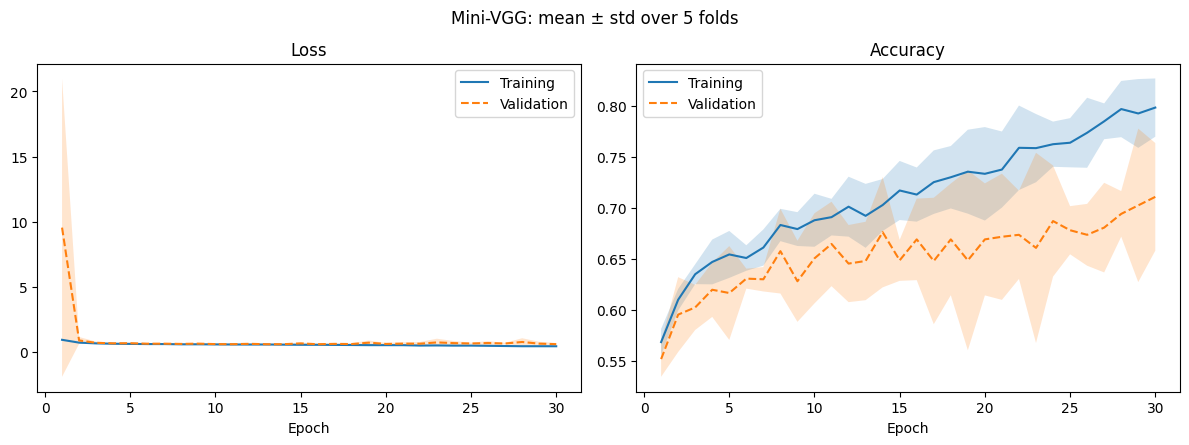

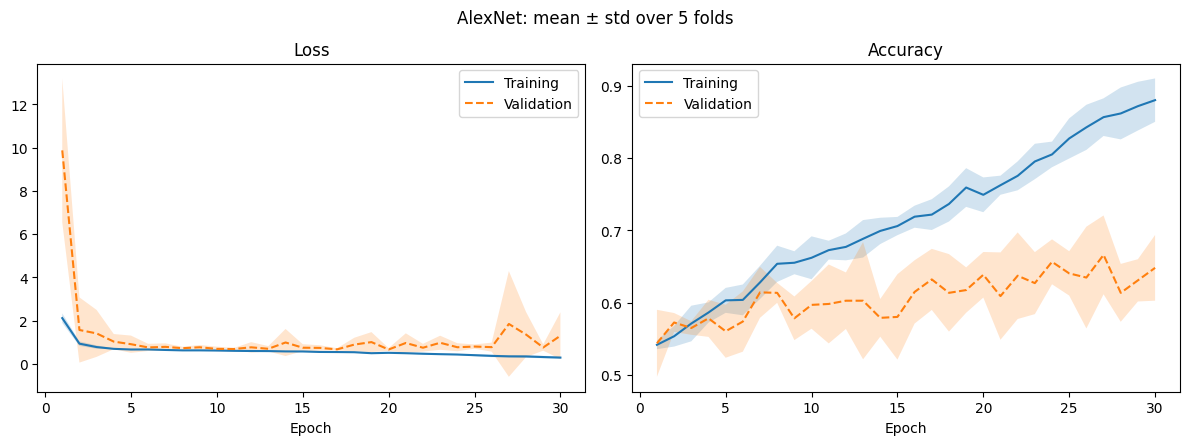

In [ ]:
def mean_std(scores):
    #gets the average accuracy scores and the standard deviation.
    return scores.mean().round(3).astype(str) + " ± " + scores.std().round(3).astype(str)

summary = pd.DataFrame({"Mini-VGG": mean_std(vgg_scores), "AlexNet": mean_std(alex_scores)})
print(summary)

def plot_cv(histories, name):
    #plots the accuracy of the two models (training accuracy vs validation)
    #also plots the loss over each epoch (full run through model)
    metrics = ['loss', 'accuracy']#, 'precision', 'recall']
    plt.figure(figsize=(12, 8))# sets the fig size
    for i, m in enumerate(metrics):
        plt.subplot(2, 2, i + 1)
        for key, style, label in [(m, '-', 'Training'), ('val_' + m, '--', 'Validation')]:
            arr = np.array([h[key] for h in histories])
            mean, std = arr.mean(axis=0), arr.std(axis=0)#assigns average and standard deviation to variables
            ep = np.arange(1, len(mean) + 1)#moves the graph up so zero is higher
            plt.plot(ep, mean, style, label=label)#plots the average on the graph
            plt.fill_between(ep, mean - std, mean + std, alpha=0.2)#fills in the standard deviation around the average
        plt.title(m.capitalize())
        plt.xlabel('Epoch')#sets the x label to epoch (number of times it ran through the data)
        plt.legend()#puts a ledgend on the graph
    plt.suptitle(f"{name}: mean ± std over {len(histories)} folds")#formats the subtitle with the number ob k folds and name of model
    plt.tight_layout()#sets the layout to a tight layout
    plt.show()#displays the plot

plot_cv(vgg_hist, "Mini-VGG")#calls the plot for VGG
plot_cv(alex_hist, "AlexNet")#calls the plot for Alex Net